# **Modelo de Aprendizaje Supervisado (Árbol de Decisión para Regresión)**

El aprendizaje supervisado permite entrenar un modelo predictivo a partir de datos históricos que contienen tanto las características de entrada (features) como una variable objetivo conocida (target). En el contexto de este sistema de transporte masivo, el propósito es predecir de forma precisa el tiempo real de viaje en minutos basándose en factores operativos clave como la distancia del trayecto, el uso de la tarjeta de transporte, las condiciones de hora pico y la presencia de transbordos.

Para lograrlo, este script implementa un Árbol de Decisión para Regresión (`DecisionTreeRegressor de sklearn`). Este algoritmo analiza automáticamente los datos y construye una estructura jerárquica de nodos y ramas (similar a un diagrama de flujo de reglas lógicas) para determinar numéricamente qué variables influyen más en el tiempo de desplazamiento.

# **El flujo metodológico incluye:**

Partición de datos (`train_test_split`): Separa el historial en datos de entrenamiento (para que la IA aprenda los patrones) y datos de prueba (para evaluar su desempeño con información nueva).

Evaluación de métricas (MSE y R²): Cuantifica el error de predicción y la capacidad de ajuste del modelo frente a la realidad.

Visualización gráfica (`matplotlib y plot_tree`): Permite contrastar visualmente los valores reales frente a las predicciones y examinar la arquitectura de decisiones generada por el algoritmo.

--- Primeras 5 filas del Dataset Histórico ---
   distancia_km  tiene_tarjeta  hora_pico  transbordo  tiempo_viaje_minutos
0      6.243562              0          0           0             25.078971
1     14.310000              1          0           0             42.831375
2     11.247915              1          0           0             32.910946
3      9.381219              1          0           0             30.965392
4      3.184261              1          0           0              7.380762
--------------------------------------------------

[EVALUACIÓN DEL MODELO]
Error Cuadrático Medio (MSE): 12.09
Coeficiente de Determinación (R²): 0.92 (Cercano a 1.0 indica excelente ajuste)


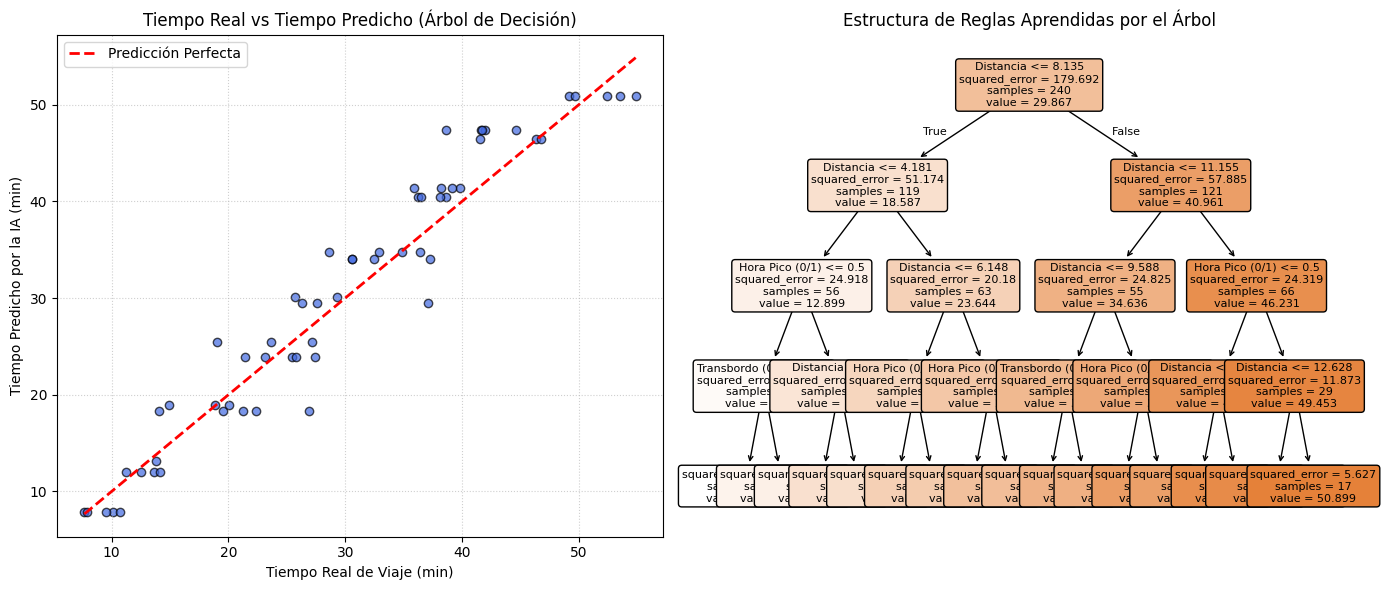

In [5]:
# Importanción de librerias utilizadas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_squared_error, r2_score

# --- PASO 1: Generación del Dataset Sintético ---
# Simulamos un historial de 300 viajes en el sistema de transporte masivo
np.random.seed(42) # Semilla para reproducibilidad

n_muestras = 300
distancia = np.random.uniform(1.0, 15.0, n_muestras) # Distancias entre 1 y 15 km
tiene_tarjeta = np.random.choice([0, 1], size=n_muestras, p=[0.2, 0.8]) # 80% tiene tarjeta
hora_pico = np.random.choice([0, 1], size=n_muestras, p=[0.5, 0.5]) # 50% probabilidad de hora pico
transbordo = np.random.choice([0, 1], size=n_muestras, p=[0.6, 0.4]) # 40% requiere transbordo

# Lógica base para calcular el tiempo real (añadiendo algo de ruido/variabilidad del mundo real)
# Base: 3 min por km + penalizaciones lógicas + ruido aleatorio
tiempo_base = distancia * 3.0
penalizacion_tarjeta = np.where(tiene_tarjeta == 0, 4.0, 0.0) # No tener tarjeta retrasa por recarga/fila
penalizacion_pico = hora_pico * 6.0                        # Tráfico en hora pico
penalizacion_transbordo = transbordo * 5.0                 # Espera de conexión
ruido = np.random.normal(0, 1.5, n_muestras)               # Variaciones imprevistas

tiempo_viaje_minutos = tiempo_base + penalizacion_tarjeta + penalizacion_pico + penalizacion_transbordo + ruido
tiempo_viaje_minutos = np.clip(tiempo_viaje_minutos, 3.0, 60.0) # Limitar entre 3 y 60 minutos

# Crear el DataFrame de Pandas
df_transporte = pd.DataFrame({
    'distancia_km': distancia,
    'tiene_tarjeta': tiene_tarjeta,
    'hora_pico': hora_pico,
    'transbordo': transbordo,
    'tiempo_viaje_minutos': tiempo_viaje_minutos
})

print("--- Primeras 5 filas del Dataset Histórico ---")
print(df_transporte.head())
print("-" * 50)

# --- PASO 2: Separación de Características (X) y Variable Objetivo (y) ---
X = df_transporte[['distancia_km', 'tiene_tarjeta', 'hora_pico', 'transbordo']]
y = df_transporte['tiempo_viaje_minutos']

# Dividir en datos de entrenamiento (80%) y prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# --- PASO 3: Entrenamiento del Modelo (Árbol de Decisión para Regresión) ---
modelo_arbol = DecisionTreeRegressor(max_depth=4, random_state=42)
modelo_arbol.fit(X_train, y_train)

# --- PASO 4: Evaluación del Modelo ---
y_pred = modelo_arbol.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"\n[EVALUACIÓN DEL MODELO]")
print(f"Error Cuadrático Medio (MSE): {mse:.2f}")
print(f"Coeficiente de Determinación (R²): {r2:.2f} (Cercano a 1.0 indica excelente ajuste)")

# --- PASO 5: Visualización de Resultados con Matplotlib ---
plt.figure(figsize=(14, 6))

# Gráfica 1: Predicciones vs Valores Reales
plt.subplot(1, 2, 1)
plt.scatter(y_test, y_pred, color='royalblue', alpha=0.7, edgecolors='k')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Predicción Perfecta')
plt.title('Tiempo Real vs Tiempo Predicho (Árbol de Decisión)')
plt.xlabel('Tiempo Real de Viaje (min)')
plt.ylabel('Tiempo Predicho por la IA (min)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)

# Gráfica 2: Estructura del Árbol de Decisión (Visualización de Reglas Aprendidas)
plt.subplot(1, 2, 2)
plot_tree(modelo_arbol,
          feature_names=['Distancia', 'Tarjeta (0/1)', 'Hora Pico (0/1)', 'Transbordo (0/1)'],
          filled=True,
          rounded=True,
          fontsize=8)
plt.title('Estructura de Reglas Aprendidas por el Árbol')

plt.tight_layout()
plt.show()

# **Modelo de Aprendizaje No Supervisado (Clustering con K-Means)**

A diferencia de los métodos supervisados, el aprendizaje no supervisado opera con datos que no poseen etiquetas previas ni una variable objetivo predefinida. El propósito principal de este enfoque es permitir que la inteligencia artificial explore la estructura interna del conjunto de datos y descubra de manera autónoma patrones ocultos, similitudes y agrupamientos naturales (clustering) sin intervención humana.

Para analizar el comportamiento operativo del sistema de transporte masivo sin una respuesta guiada, se emplea el algoritmo K-Means. Este método agrupa las observaciones multidimensionales en un número determinado de clústeres basándose en las distancias estadísticas entre los registros.

# **Los componentes esenciales de esta fase son:**

Estandarización de datos (`StandardScaler`): Dado que las variables combinan magnitudes muy distintas (kilómetros, variables binarias de 0 y 1, y minutos de viaje), el escalador normaliza los datos para evitar que una sola variable distorsione las distancias geométricas del agrupamiento.

Agrupamiento K-Means: Clasifica los registros de viajes en perfiles operativos distintos (por ejemplo, viajes cortos fluidos frente a trayectos largos complejos).

Visualización en plano cartesiano (`matplotlib`): Representa mediante una gráfica de dispersión coloreada cómo la IA separó de forma autónoma las características del sistema masivo.

--- Primeras 5 filas con el Cluster asignado por la IA ---
   distancia_km  tiene_tarjeta  hora_pico  transbordo  tiempo_viaje_minutos  \
0      6.243562              0          0           0             25.078971   
1     14.310000              1          0           0             42.831375   
2     11.247915              1          0           0             32.910946   
3      9.381219              1          0           0             30.965392   
4      3.184261              1          0           0              7.380762   

   cluster  
0        1  
1        2  
2        2  
3        2  
4        0  
--------------------------------------------------


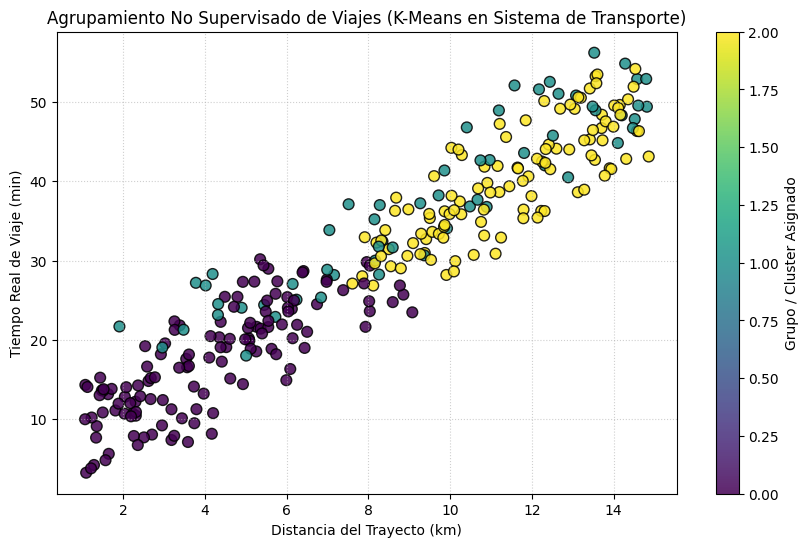

In [1]:
# Importanción de librerias utilizadas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# --- PASO 1: Generación del Dataset (Mismo del ejercicio anterior) ---
np.random.seed(42)
n_muestras = 300

distancia = np.random.uniform(1.0, 15.0, n_muestras)
tiene_tarjeta = np.random.choice([0, 1], size=n_muestras, p=[0.2, 0.8])
hora_pico = np.random.choice([0, 1], size=n_muestras, p=[0.5, 0.5])
transbordo = np.random.choice([0, 1], size=n_muestras, p=[0.6, 0.4])

# Lógica base para simular el comportamiento físico del sistema
tiempo_base = distancia * 3.0
penalizacion_tarjeta = np.where(tiene_tarjeta == 0, 4.0, 0.0)
penalizacion_pico = hora_pico * 6.0
penalizacion_transbordo = transbordo * 5.0
ruido = np.random.normal(0, 1.5, n_muestras)

tiempo_viaje_minutos = tiempo_base + penalizacion_tarjeta + penalizacion_pico + penalizacion_transbordo + ruido
tiempo_viaje_minutos = np.clip(tiempo_viaje_minutos, 3.0, 60.0)

# Creación del DataFrame
df_transporte = pd.DataFrame({
    'distancia_km': distancia,
    'tiene_tarjeta': tiene_tarjeta,
    'hora_pico': hora_pico,
    'transbordo': transbordo,
    'tiempo_viaje_minutos': tiempo_viaje_minutos
})

# --- PASO 2: Preparación y Escalado de Datos (Requisito para Clustering) ---
# En aprendizaje no supervisado utilizamos todas las variables disponibles como un bloque multivariado (X)
X = df_transporte[['distancia_km', 'tiene_tarjeta', 'hora_pico', 'transbordo', 'tiempo_viaje_minutos']]

# El StandardScaler normaliza las escalas (ya que los km van de 1 a 15 y el tiempo de 3 a 60)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# --- PASO 3: Entrenamiento del Modelo No Supervisado (K-Means) ---
# Agruparemos los viajes en 3 perfiles operativos distintos descubiertos por el algoritmo
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df_transporte['cluster'] = kmeans.fit_predict(X_scaled)

print("--- Primeras 5 filas con el Cluster asignado por la IA ---")
print(df_transporte.head())
print("-" * 50)

# --- PASO 4: Visualización de Resultados con Matplotlib ---
plt.figure(figsize=(10, 6))

# Graficamos la relación entre Distancia y Tiempo de Viaje, coloreando según el grupo (cluster) encontrado
scatter = plt.scatter(
    df_transporte['distancia_km'],
    df_transporte['tiempo_viaje_minutos'],
    c=df_transporte['cluster'],
    cmap='viridis',
    s=60,
    edgecolors='k',
    alpha=0.85
)

plt.title('Agrupamiento No Supervisado de Viajes (K-Means en Sistema de Transporte)')
plt.xlabel('Distancia del Trayecto (km)')
plt.ylabel('Tiempo Real de Viaje (min)')
plt.colorbar(scatter, label='Grupo / Cluster Asignado')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()